In [ ]:
### Prediksi Kalori Menu McDonald's dengan Linear Regression
#Tujuan: Menentukan apa yang ingin kita prediksi dan bagaimana data digunakan.

#Pada Project ini:
# - Masalah: Belum mengetahui estimasi kalori berdasarkan kandungan nutrisi suatu menu.
# - Tujuan: Membuat model untuk memprediksi jumlah kalori menu McDonald's.
# - Metode: Linear Regression.
# - Target prediksi: Calories.
# - Fitur: Total Fat, Carbohydrates, dan Protein.

In [ ]:
# A. Data Understanding
# ---------- 1. Import library ----------
import pandas as pd               # Pengolahan data
import numpy as np
import matplotlib.pyplot as plt   # Visualisasi data
import seaborn as sns
from sklearn.model_selection import train_test_split    # Machine Learning
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (     # Evaluasi model
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

In [ ]:
# ---------- 2. Membaca Dataset ----------
data = pd.read_csv('menu.csv')

In [ ]:
# ---------- 3. Melihat Isi Dataset ----------
print(data.head())              # Melihat 5 baris pertama
print(data.tail())              # Melihat 5 baris terakhir
print(data.shape)               # Melihat jumlah baris dan kolom
data.info()                     # Melihat informasi dataset
print(data.columns.tolist())    # Melihat nama seluruh kolom

    Category                              Item    Serving Size  Calories  \
0  Breakfast                      Egg McMuffin  4.8 oz (136 g)       300   
1  Breakfast                 Egg White Delight  4.8 oz (135 g)       250   
2  Breakfast                  Sausage McMuffin  3.9 oz (111 g)       370   
3  Breakfast         Sausage McMuffin with Egg  5.7 oz (161 g)       450   
4  Breakfast  Sausage McMuffin with Egg Whites  5.7 oz (161 g)       400   

   Calories from Fat  Total Fat  Total Fat (% Daily Value)  Saturated Fat  \
0                120       13.0                         20            5.0   
1                 70        8.0                         12            3.0   
2                200       23.0                         35            8.0   
3                250       28.0                         43           10.0   
4                210       23.0                         35            8.0   

   Saturated Fat (% Daily Value)  Trans Fat  ...  Carbohydrates  \
0            

In [ ]:
# ---------- 4. Melihat Kategori Menu ----------
print(data['Category'].value_counts())

Category
Coffee & Tea          95
Breakfast             42
Smoothies & Shakes    28
Chicken & Fish        27
Beverages             27
Beef & Pork           15
Snacks & Sides        13
Desserts               7
Salads                 6
Name: count, dtype: int64


In [ ]:
# ---------- 5. Melihat Statistik Deskriptif Awal ----------
print(data.describe().T)

                               count        mean         std  min      25%  \
Calories                       260.0  368.269231  240.269886  0.0  210.000   
Calories from Fat              260.0  127.096154  127.875914  0.0   20.000   
Total Fat                      260.0   14.165385   14.205998  0.0    2.375   
Total Fat (% Daily Value)      260.0   21.815385   21.885199  0.0    3.750   
Saturated Fat                  260.0    6.007692    5.321873  0.0    1.000   
Saturated Fat (% Daily Value)  260.0   29.965385   26.639209  0.0    4.750   
Trans Fat                      260.0    0.203846    0.429133  0.0    0.000   
Cholesterol                    260.0   54.942308   87.269257  0.0    5.000   
Cholesterol (% Daily Value)    260.0   18.392308   29.091653  0.0    2.000   
Sodium                         260.0  495.750000  577.026323  0.0  107.500   
Sodium (% Daily Value)         260.0   20.676923   24.034954  0.0    4.750   
Carbohydrates                  260.0   47.346154   28.252232  0.

In [ ]:
# B. Data Preparation (Data Cleaning)
# ---------- 1. Memeriksa Missing Value ----------
print(data.isnull().sum())                                # Memeriksa jumlah data kosong setiap kolom
print("Total Missing Values:", data.isnull().sum().sum()) # Menghitung total data kosong
print("Total Data Duplikat:", data.duplicated().sum())    # Menghitung jumlah data duplikat
data = data.drop_duplicates().copy()                      # Menghapus data duplikat

Category                         0
Item                             0
Serving Size                     0
Calories                         0
Calories from Fat                0
Total Fat                        0
Total Fat (% Daily Value)        0
Saturated Fat                    0
Saturated Fat (% Daily Value)    0
Trans Fat                        0
Cholesterol                      0
Cholesterol (% Daily Value)      0
Sodium                           0
Sodium (% Daily Value)           0
Carbohydrates                    0
Carbohydrates (% Daily Value)    0
Dietary Fiber                    0
Dietary Fiber (% Daily Value)    0
Sugars                           0
Protein                          0
Vitamin A (% Daily Value)        0
Vitamin C (% Daily Value)        0
Calcium (% Daily Value)          0
Iron (% Daily Value)             0
dtype: int64
Total Missing Values: 0
Total Data Duplikat: 0


In [ ]:
# ---------- 2. Menentukan Fitur ----------
features = [
    'Total Fat',
    'Carbohydrates',
    'Protein'
]
target = 'Calories'   # Menentukan target

In [ ]:
# ---------- 3. Membersihkan Missing Values ----------
jumlah_awal = len(data)   # Menghapus baris yang kosong pada fitur dan target
data = data.dropna(subset=features + [target]).copy()
jumlah_akhir = len(data)
print("Data sebelum cleaning:", jumlah_awal)
print("Data setelah cleaning:", jumlah_akhir)
print("Data yang dihapus:", jumlah_awal - jumlah_akhir)

Data sebelum cleaning: 260
Data setelah cleaning: 260
Data yang dihapus: 0


In [ ]:
# ---------- 4. Memeriksa Data Cleaning ----------
target = 'Calories'
print(data[features + [target]].isnull().sum())   # Memeriksa kembali missing values
print("Shape setelah cleaning:", data.shape)      # Melihat jumlah data setelah cleaning
print(data[features + [target]].describe().T)     # Melihat statistik setelah cleaning

Total Fat        0
Carbohydrates    0
Protein          0
Calories         0
dtype: int64
Shape setelah cleaning: (260, 24)
               count        mean         std  min      25%    50%     75%  \
Total Fat      260.0   14.165385   14.205998  0.0    2.375   11.0   22.25   
Carbohydrates  260.0   47.346154   28.252232  0.0   30.000   44.0   60.00   
Protein        260.0   13.338462   11.426146  0.0    4.000   12.0   19.00   
Calories       260.0  368.269231  240.269886  0.0  210.000  340.0  500.00   

                  max  
Total Fat       118.0  
Carbohydrates   141.0  
Protein          87.0  
Calories       1880.0  


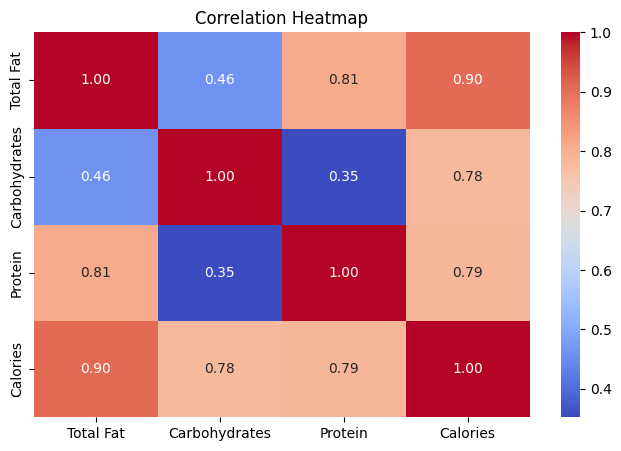

In [ ]:
# C. Exploratory Data Analysis (EDA)
# ---------- 1. Melihat Korelasi Antarvariabel ----------
correlation = data[features + [target]].corr()    # Menghitung korelasi
plt.figure(figsize=(8, 5))                        # Membuat heatmap
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

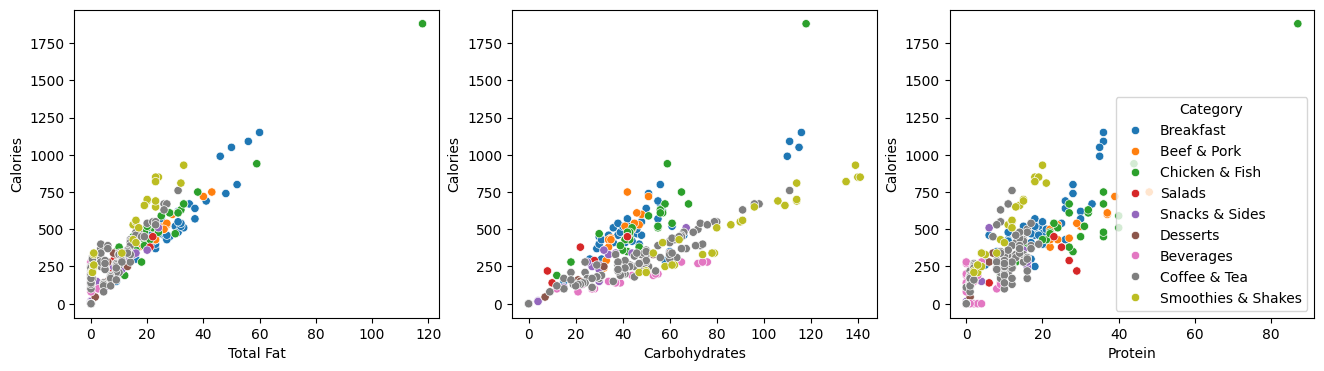

In [ ]:
# ---------- 2. Melihat Hubungan terhadap Calories ----------
# Scatter plot fitur utama terhadap kalori
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, f in zip(ax, ['Total Fat', 'Carbohydrates', 'Protein']):
    sns.scatterplot(data=data, x=f, y='Calories', hue='Category', ax=a, legend=(f == 'Protein'))
plt.show()

In [ ]:
# D. Modeling
# ---------- 1. Memisahkan Fitur dan Target ----------
X = data[features]  # Variabel input
y = data[target]    # Variabel target

In [ ]:
# ---------- 2. Membagi Data Training dan Testing ----------
#80% latih(training) dan 20% uji(testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 208
Jumlah data testing: 52


In [ ]:
# ---------- 3. Membuat Model Baseline ----------
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

In [ ]:
# ---------- 4. Membuat Model Linear Regression ----------
model = LinearRegression()    # Membuat model
model.fit(X_train, y_train)   # Melatih model menggunakan data training
y_pred = model.predict(X_test)  # Melakukan prediksi pada data testing

In [ ]:
# ---------- 5. Melihat Koefisien Model ----------
print("Intercept:", model.intercept_)

koefisien = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
})

print(koefisien)

Intercept: -2.1160894045955843
         Feature  Coefficient
0      Total Fat     9.002998
1  Carbohydrates     3.988871
2        Protein     4.054709


In [ ]:
# E. Evaluation (Evaluasi Model)
# ---------- 1. Menghitung MAE, MSE, RMSE, dan R² ----------
mae = mean_absolute_error(y_test, y_pred)   # MAE (Mengukur rata-rata selisih absolut prediksi dengan nilai asli)
mse = mean_squared_error(y_test, y_pred)    # MSE (Mengukur rata-rata kesalahan kuadrat)
rmse = np.sqrt(mse)                         # RMSE (Mengukur kesalahan prediksi dalam satuan kalori)
r2 = r2_score(y_test, y_pred)               # R-squared (Mengukur seberapa banyak variasi target dapat dijelaskan model)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3.7236075049432547
MSE: 27.166420663787015
RMSE: 5.212141658069839
R2 Score: 0.9993428663117916


In [ ]:
# ---------- 2. Menghitung MAPE ----------
mask = y_test > 0   # Mengambil data aktual yang lebih besar dari 0
mape = mean_absolute_percentage_error(      # Menghitung MAPE
    y_test[mask],
    y_pred[mask]
) * 100

print("MAPE:", mape, "%")

MAPE: 1.5622825456881584 %


In [ ]:
# ---------- 3. Membandingkan Baseline dengan Linear Regression----------
# Evaluasi baseline
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)
baseline_r2 = r2_score(y_test, y_pred_baseline)

# Membuat tabel perbandingan
comparison = pd.DataFrame({
    'Model': ['Baseline', 'Linear Regression'],
    'MAE': [baseline_mae, mae],
    'RMSE': [baseline_rmse, rmse],
    'R2 Score': [baseline_r2, r2]
})

print(comparison)

               Model         MAE        RMSE  R2 Score
0           Baseline  162.659024  203.605527 -0.002768
1  Linear Regression    3.723608    5.212142  0.999343


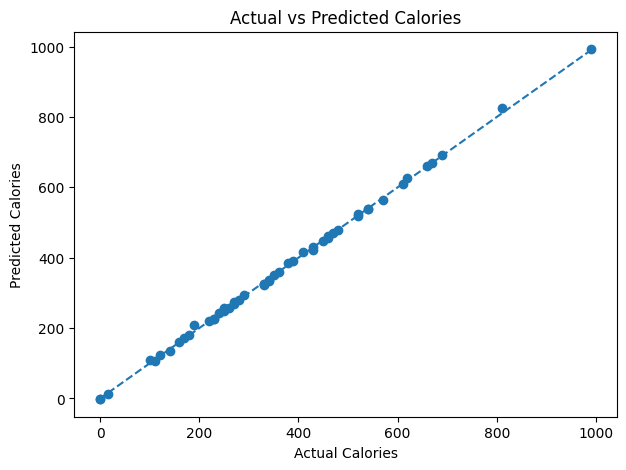

In [ ]:
# ---------- 4. Visualisasi Actual vs Predicted----------
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Calories')
plt.ylabel('Predicted Calories')
plt.title('Actual vs Predicted Calories')

# Garis prediksi ideal
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.show()

In [ ]:
# ---------- 5. Membandingkan Performa Training dan Testing----------
y_train_pred = model.predict(X_train)     # Prediksi data training

# Menghitung R2
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

print("Training R2:", train_r2)
print("Testing R2:", test_r2)

Training R2: 0.9994953619524066
Testing R2: 0.9993428663117916


In [ ]:
## F. Deployment (Uji Coba Prediksi Menu Baru) ##
# Membuat data menu baru
menu_baru = pd.DataFrame([{
    'Total Fat': 50,
    'Carbohydrates': 50,
    'Protein': 50
}])

# Melakukan prediksi
prediksi = model.predict(menu_baru)

print("Prediksi Calories:", prediksi[0])

Prediksi Calories: 850.212801845591


In [ ]:
# Import library Joblib
import joblib

# Menyimpan model
joblib.dump(model, 'model_kalori.pkl')

print("Model berhasil disimpan!")

# Install Streamlit
!pip install -q streamlit




Model berhasil disimpan!


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Memuat model
model = joblib.load('model_kalori.pkl')

# Judul aplikasi
st.title("Prediksi Kalori Menu McDonald's")

st.write(
    "Masukkan kandungan nutrisi untuk memprediksi jumlah kalori menu."
)

st.divider()

# Input nutrisi
st.subheader("Masukkan Kandungan Nutrisi")

total_fat = st.number_input(
    "Total Fat (gram)",
    min_value=0.0,
    value=50.0
)

carbohydrates = st.number_input(
    "Carbohydrates (gram)",
    min_value=0.0,
    value=50.0
)

protein = st.number_input(
    "Protein (gram)",
    min_value=0.0,
    value=50.0
)

# Tombol prediksi
if st.button("Prediksi Kalori"):

    menu_baru = pd.DataFrame([{
        'Total Fat': total_fat,
        'Carbohydrates': carbohydrates,
        'Protein': protein
    }])

    prediksi = model.predict(menu_baru)

    st.success("Prediksi berhasil!")

    st.metric(
        "Estimasi Kalori",
        f"{prediksi[0]:.2f} kcal"
    )


import os

print(os.listdir('/content'))

Overwriting app.py


In [ ]:
!pip install -q streamlit

In [ ]:
import subprocess
import time

log_file = open('/content/streamlit.log', 'w')

process = subprocess.Popen(
    [
        'streamlit', 'run', '/content/app.py',
        '--server.port=8501',
        '--server.address=0.0.0.0',
        '--server.headless=true'
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("Status:", process.poll())

Status: 1


In [ ]:
!cat /content/streamlit.log



2026-11-01 19:27:32.453 Port 8501 is not available


In [ ]:
!streamlit --version

Streamlit, version 1.66.1


In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>